# Predicting New User Uninstallation in a Digital Wallet App (XGBoost + SHAP)

Code for the IEEE ICIMTech 2026 paper by **Fernando Lee** & Novan Zulkarnain ([DOI](https://doi.org/10.1109/ICIMTech202671078.2026.11698998)).

> **Data note:** this public version runs on a **synthetic dataset** (`synthetic_new_users.csv`) with the same schema as the original. Rows were resampled and perturbed, dates moved to a fictitious month and partner names generalized, so **numbers here differ from the paper** and do not reflect any real company figures.

# 1. Data Preprocessing
---

### STEP 1.1 - DATA CLEANING

In [1]:
import pandas as pd
import numpy as np

#### Load Data

In [2]:
df = pd.read_csv("synthetic_new_users.csv", sep=";")
df

,Register Date,Media Source,KYC,Click_PN,Click_Cards,Cash In,Top Up ( Amount),Payment or Not,Product Payment,Product (Amount),Status User
0,05/01/2024,Paid,Classic,No Click,No Click Cards,No Top Up,0,No Payment,NaN,0,Uninstall
1,16/01/2024,Organic,Classic,No Click,No Click Cards,No Top Up,0,No Payment,NaN,0,Install
2,02/01/2024,Organic,Classic,No Click,No Click Cards,No Top Up,0,No Payment,NaN,0,Install
3,05/01/2024,Organic,Classic,No Click,No Click Cards,No Top Up,0,No Payment,NaN,0,Install
4,14/01/2024,Organic,Classic,No Click,No Click Cards,No Top Up,0,No Payment,NaN,0,Install
...,...,...,...,...,...,...,...,...,...,...,...
49995,07/01/2024,Organic,Preffered,Click,Click Cards,Top Up,356000,Payment,QR Payment,28000,Install
49996,16/01/2024,Organic,Classic,No Click,No Click Cards,No Top Up,0,No Payment,NaN,0,Install
49997,13/01/2024,Paid,Classic,No Click,No Click Cards,No Top Up,0,No Payment,NaN,0,Uninstall
49998,25/01/2024,Organic,Classic,No Click,No Click Cards,No Top Up,0,No Payment,NaN,0,Install


#### Drop kolom

In [3]:
if 'User_ID' in df.columns:
    df = df.drop(columns=['User_ID'])

#### Standardisasi nama kolom

In [4]:
df.columns = (
    df.columns.str.strip()                # hapus spasi awal/akhir
               .str.replace(' ', '_')     # ganti spasi jadi underscore
               .str.replace(r'[\(\)]', '', regex=True)  # hapus tanda kurung
)

#### Format kolom tanggal

In [5]:
df['Register_Date'] = pd.to_datetime(df['Register_Date'], format='%d/%m/%Y', errors='coerce')

#### Bersihkan kolom numerik

In [6]:
def clean_amount(x):
    if pd.isna(x) or x == '':
        return 0.0
    if isinstance(x, str):
        x = x.replace('.', '').replace(',', '.')
    try:
        return float(x)
    except ValueError:
        return 0.0

In [7]:
df.columns = (
    df.columns.str.strip()
              .str.replace(' ', '_')
              .str.replace(r'[\(\)]', '', regex=True)
)

print("✅ Cleaned column names:", df.columns.tolist())

✅ Cleaned column names: ['Register_Date', 'Media_Source', 'KYC', 'Click_PN', 'Click_Cards', 'Cash_In', 'Top_Up__Amount', 'Payment_or_Not', 'Product_Payment', 'Product_Amount', 'Status_User']


In [8]:
possible_topup_cols = [c for c in df.columns if 'Top' in c and 'Amount' in c]
possible_product_cols = [c for c in df.columns if 'Product' in c and 'Amount' in c]

print("Detected columns:", possible_topup_cols, possible_product_cols)

Detected columns: ['Top_Up__Amount'] ['Product_Amount']


In [9]:
for col in possible_topup_cols + possible_product_cols:
    df[col] = df[col].apply(clean_amount)

#### Handling Missing Values

In [10]:
cat_cols = df.select_dtypes(include='object').columns
df[cat_cols] = df[cat_cols].fillna('Unknown')

C:\Users\925003640\AppData\Local\Temp\ipykernel_19812\1370435292.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include='object').columns


In [11]:
# Isi nilai kosong di kolom numerik dengan 0
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
df[num_cols] = df[num_cols].fillna(0)

#### Sanity Check

In [12]:
print("Dataset cleaned summary:")
print(df.info())
print("\nSample data:\n", df.head(3))

Dataset cleaned summary:
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Register_Date    50000 non-null  datetime64[us]
 1   Media_Source     50000 non-null  str           
 2   KYC              50000 non-null  str           
 3   Click_PN         50000 non-null  str           
 4   Click_Cards      50000 non-null  str           
 5   Cash_In          50000 non-null  str           
 6   Top_Up__Amount   50000 non-null  float64       
 7   Payment_or_Not   50000 non-null  str           
 8   Product_Payment  50000 non-null  str           
 9   Product_Amount   50000 non-null  float64       
 10  Status_User      50000 non-null  str           
dtypes: datetime64[us](1), float64(2), str(8)
memory usage: 4.2 MB
None

Sample data:
   Register_Date Media_Source      KYC  Click_PN     Click_Cards    Cash_In  \
0    2024-01-05        

### STEP 1.2 - Feature Engineering

#### Map binary / boolean features

In [13]:
binary_map_click = {'Click': 1, 'No Click': 0}
binary_map_cards = {'Click Cards': 1, 'No Click Cards': 0}
binary_map_topup = {'Top Up': 1, 'No Top Up': 0}
binary_map_payment = {'Payment': 1, 'No Payment': 0}

In [14]:
df['Click_PN'] = df['Click_PN'].map(binary_map_click).fillna(0)
df['Click_Cards'] = df['Click_Cards'].map(binary_map_cards).fillna(0)
df['Cash_In'] = df['Cash_In'].map(binary_map_topup).fillna(0)
df['Payment_or_Not'] = df['Payment_or_Not'].map(binary_map_payment).fillna(0)

#### Encode Target Variable

In [15]:
# Install = 0 (retained), Uninstall = 1 (churn)
df['Status_User'] = df['Status_User'].map({'Install': 0, 'Uninstall': 1})

#### One-Hot Encoding categorical columns

In [16]:
categorical_cols = ['Media_Source', 'KYC', 'Product_Payment']

df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

#### Fitur tambahan

In [17]:
# a. User engagement score: kombinasi click dan transaksi
df['Engagement_Score'] = (
    df['Click_PN'] + df['Click_Cards'] + df['Cash_In'] + df['Payment_or_Not']
)

# b. Total transaksi: jumlah top up + product amount
df['Total_Transaction_Amount'] = df['Top_Up__Amount'] + df['Product_Amount']

# c. Hari registrasi (weekday), bisa mempengaruhi perilaku user awal
df['Register_Weekday'] = df['Register_Date'].dt.weekday  # 0=Senin, 6=Minggu

C:\Users\925003640\AppData\Local\Temp\ipykernel_19812\113558006.py:10: Pandas4Warning: Series.dt.weekday is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['Register_Weekday'] = df['Register_Date'].dt.weekday  # 0=Senin, 6=Minggu


#### Drop kolom tanggal

In [18]:
df = df.drop(columns=['Register_Date'])
df = df.drop(columns=['User_ID_New_User'], errors='ignore')

#### Sanity Check

In [19]:
print("✅ Feature Engineering complete!")
print(f"Final shape: {df.shape}")
print("\nColumns after transformation:\n", list(df.columns))
print("\nSample rows:\n", df.head(3))

✅ Feature Engineering complete!
Final shape: (50000, 20)

Columns after transformation:
 ['Click_PN', 'Click_Cards', 'Cash_In', 'Top_Up__Amount', 'Payment_or_Not', 'Product_Amount', 'Status_User', 'Media_Source_Paid', 'KYC_Preffered', 'Product_Payment_Mobile & Telco', 'Product_Payment_Multifinance', 'Product_Payment_Online Payment', 'Product_Payment_Other Bills', 'Product_Payment_QR Payment', 'Product_Payment_Transfer', 'Product_Payment_Unknown', 'Product_Payment_Utilities', 'Engagement_Score', 'Total_Transaction_Amount', 'Register_Weekday']

Sample rows:
    Click_PN  Click_Cards  Cash_In  Top_Up__Amount  Payment_or_Not  \
0         0            0        0             0.0               0   
1         0            0        0             0.0               0   
2         0            0        0             0.0               0   

   Product_Amount  Status_User  Media_Source_Paid  KYC_Preffered  \
0             0.0            1               True          False   
1             0.0       

# 2. Train-Test Split
---

In [20]:
from sklearn.model_selection import train_test_split, StratifiedKFold

# Drop rows where 'Status_User' is NaN before separating features & target
df.dropna(subset=['Status_User'], inplace=True)

# Separate features & target
X = df.drop(columns=["Status_User"])
y = df["Status_User"]

# Ensure y is integer type for stratification
y = y.astype(int)

# 1️⃣ Split ke train + test (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# 2️⃣ Buat StratifiedKFold di training set (untuk CV)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

C:\Users\925003640\AppData\Local\Temp\ipykernel_19812\3870960723.py:4: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(subset=['Status_User'], inplace=True)


# 3. Model Training
---

In [21]:
from xgboost import XGBClassifier

#### 3.1 Baseline Model

#### Rasio Imbalance

In [22]:
pos = np.sum(y_train == 1)
neg = np.sum(y_train == 0)

In [23]:
if pos == 0:
    scale_pos_weight = 1.0
else:
    scale_pos_weight = neg / pos

In [24]:
print("Positive class (1):", pos)
print("Negative class (0):", neg)
print("scale_pos_weight:", scale_pos_weight)

Positive class (1): 8400
Negative class (0): 31600
scale_pos_weight: 3.761904761904762


#### Baseline Model

In [25]:
xgb = XGBClassifier(
    # capacity / kompleksitas model
    n_estimators=300,          # jumlah tree boosting
    max_depth=6,              # kedalaman tree (kontrol kompleksitas)
    learning_rate=0.05,       # eta kecil = training lebih stabil
    min_child_weight=1,       # minimum total hessian per leaf, nanti bisa dinaikkan pas tuning

    # regularization (buat cegah overfit)
    subsample=0.8,            # bootstrap row sampling
    colsample_bytree=0.8,     # feature subsampling per tree
    reg_lambda=1.0,           # L2 penalty
    reg_alpha=0.0,            # L1 penalty (bisa >0 utk sparse feature)

    # imbalance handling
    scale_pos_weight=scale_pos_weight,

    # runtime / stability
    tree_method="hist",       # lebih cepat & memory efficient (CPU friendly)
    predictor="auto",
    n_jobs=-1,                # pakai semua core

    # eval metric
    eval_metric="logloss",    # bisa diganti "auc" kalau fokus ranking uninstall

    random_state=42
)

#### Fit Model

In [26]:
xgb.fit(
    X_train,
    y_train,
    eval_set=[(X_train, y_train), (X_test, y_test)],
    verbose=False
)

C:\Test_Pyhton\portfolio\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [08:15:44] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "predictor" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


#### Evaluasi Baseline

In [27]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Hard prediction
y_pred = xgb.predict(X_test)

# Probabilitas positive class (Uninstall)
y_proba = xgb.predict_proba(X_test)[:, 1]

In [28]:
print("=== Confusion Matrix ===")
print(confusion_matrix(y_test, y_pred))

print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred, digits=4))

print("\nROC-AUC:", roc_auc_score(y_test, y_proba))

=== Confusion Matrix ===
[[6699 1201]
 [ 765 1335]]

=== Classification Report ===
              precision    recall  f1-score   support

           0     0.8975    0.8480    0.8720      7900
           1     0.5264    0.6357    0.5759      2100

    accuracy                         0.8034     10000
   macro avg     0.7120    0.7418    0.7240     10000
weighted avg     0.8196    0.8034    0.8099     10000


ROC-AUC: 0.7801639843279083


#### Feature Importance

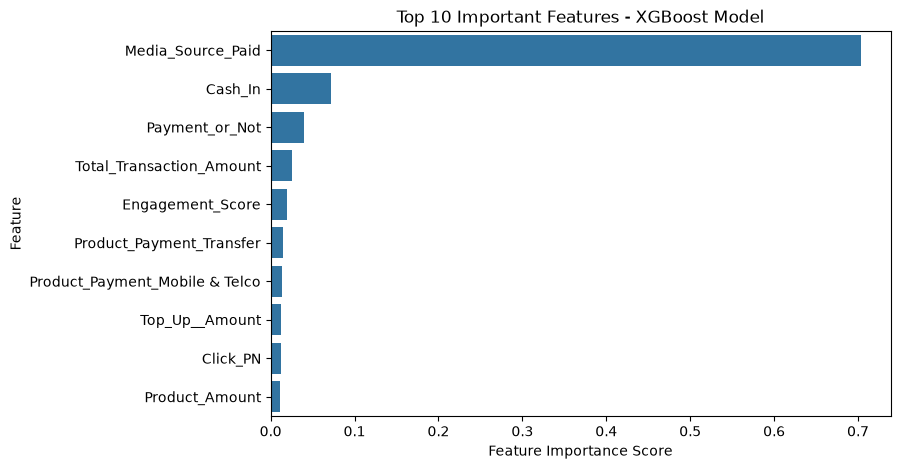

In [29]:
# Feature importance dari XGboost
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plot_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': xgb.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(8,5))
sns.barplot(x='Importance', y='Feature', data=plot_importance.head(10))
plt.title('Top 10 Important Features - XGBoost Model') # Updated title
plt.xlabel('Feature Importance Score')
plt.ylabel('Feature')
plt.show()

C:\Users\925003640\AppData\Local\Temp\ipykernel_19812\3603508795.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


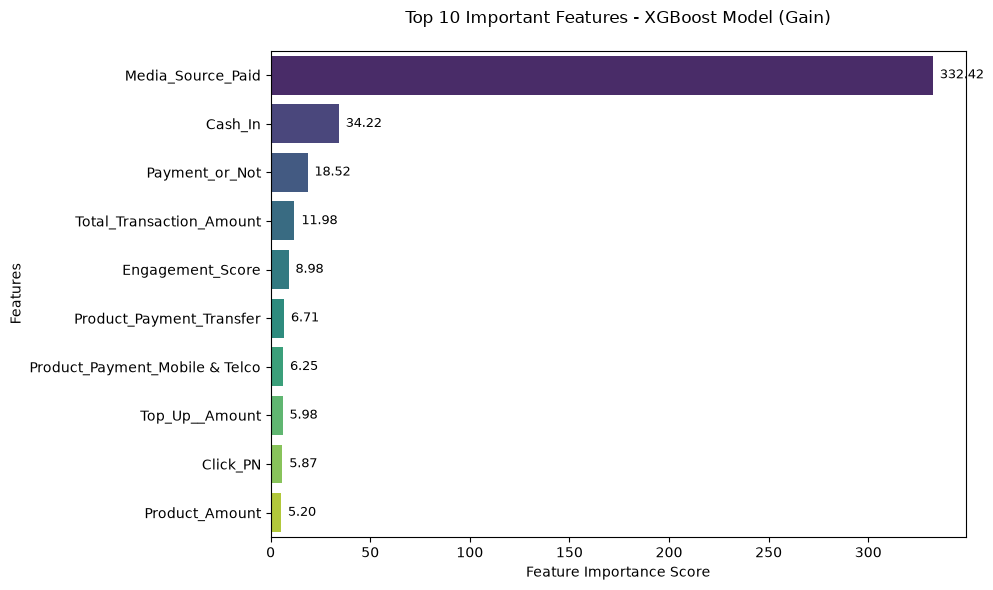

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Ambil importance dan buat DataFrame
importance_scores = xgb.get_booster().get_score(importance_type='gain')
plot_importance = pd.DataFrame({
    'Feature': list(importance_scores.keys()),
    'Importance': list(importance_scores.values())
}).sort_values(by='Importance', ascending=False)

# 2. Visualisasi
plt.figure(figsize=(10, 6))
# Gunakan palet warna 'viridis' atau 'mako' agar lebih modern
ax = sns.barplot(
    x='Importance',
    y='Feature',
    data=plot_importance.head(10),
    palette='viridis'
)

# 3. Opsional: Gunakan Skala Logaritmik jika perbedaan nilai masih terlalu ekstrem
# ax.set_xscale('log')

# 4. Tambahkan label nilai di ujung bar (dibulatkan agar rapi)
for p in ax.patches:
    ax.annotate(f'{p.get_width():.2f}',
                (p.get_width(), p.get_y() + p.get_height() / 2),
                ha='left', va='center',
                xytext=(5, 0),
                textcoords='offset points',
                fontsize=9)

plt.title('Top 10 Important Features - XGBoost Model (Gain)', pad=20)
plt.xlabel('Feature Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

#### 3.2 Hyperparameter Tuning

In [31]:
import optuna
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier
import numpy as np

C:\Test_Pyhton\portfolio\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [32]:
# Hitung imbalance ratio sekali di awal
pos = np.sum(y_train == 1)
neg = np.sum(y_train == 0)
if pos == 0:
    base_scale_pos_weight = 1.0
else:
    base_scale_pos_weight = neg / pos

In [33]:
print("Positives (uninstall=1):", pos)
print("Negatives (install=0):", neg)
print("Base scale_pos_weight:", base_scale_pos_weight)

Positives (uninstall=1): 8400
Negatives (install=0): 31600
Base scale_pos_weight: 3.761904761904762


In [34]:
def objective(trial):
    """
    Fungsi ini dipanggil Optuna setiap trial.
    Dia akan:
    - sampling hyperparam
    - training XGBoost pakai CV
    - return mean ROC-AUC (semakin tinggi semakin bagus)
    """

    # === 1. Sample hyperparameters ===
    params = {
        # kapasitas model
        "n_estimators": trial.suggest_int("n_estimators", 200, 600),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "min_child_weight": trial.suggest_float("min_child_weight", 1.0, 10.0),

        # regularization / generalization
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),  # L2
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-4, 5.0, log=True),     # L1

        # class imbalance
        # kita boleh allow Optuna untuk scale ini sekitar base ratio
        "scale_pos_weight": trial.suggest_float(
            "scale_pos_weight",
            0.5 * base_scale_pos_weight,
            2.0 * base_scale_pos_weight
        ),

        # runtime / deterministik
        "tree_method": "hist",
        "n_jobs": -1,
        "random_state": 42,
        "eval_metric": "logloss",  # training metric internal; eval external pakai ROC-AUC
        "predictor": "auto",
        "verbosity": 0
    }

    # === 2. Cross-validation manual ===
    cv_scores = []

    for fold_idx, (train_idx, valid_idx) in enumerate(skf.split(X_train, y_train)):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[valid_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[valid_idx]

        model = XGBClassifier(**params)

        model.fit(
            X_tr,
            y_tr,
            verbose=False
        )

        # Prediksi probabilitas kelas positif (uninstall = 1)
        y_val_proba = model.predict_proba(X_val)[:, 1]

        # ROC-AUC fold ini
        fold_auc = roc_auc_score(y_val, y_val_proba)
        cv_scores.append(fold_auc)

    # === 3. Aggregasi score antar fold ===
    mean_auc = np.mean(cv_scores)

    # (opsional) log detail per trial
    trial.set_user_attr("cv_scores", cv_scores)

    return mean_auc


In [35]:
study = optuna.create_study(
    direction="maximize",
    study_name="xgb_uninstall_prediction",
    sampler=optuna.samplers.TPESampler(seed=42)
)

study.optimize(objective, n_trials=50, show_progress_bar=True)


[I 2026-11-18 08:15:46,982] A new study created in memory with name: xgb_uninstall_prediction


  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:04<?, ?it/s]

Best trial: 0. Best value: 0.776606:   0%|          | 0/50 [00:04<?, ?it/s]

Best trial: 0. Best value: 0.776606:   2%|▏         | 1/50 [00:04<04:04,  5.00s/it]

[I 2026-11-18 08:15:51,976] Trial 0 finished with value: 0.7766061727697409 and parameters: {'n_estimators': 350, 'max_depth': 10, 'learning_rate': 0.08960785365368121, 'min_child_weight': 6.387926357773329, 'subsample': 0.6624074561769746, 'colsample_bytree': 0.662397808134481, 'reg_lambda': 0.0017073967431528124, 'reg_alpha': 1.1752647960576206, 'scale_pos_weight': 5.272958518646202}. Best is trial 0 with value: 0.7766061727697409.


... (193 outputs left out)

Best trial: 4. Best value: 0.782251:  98%|█████████▊| 49/50 [04:32<00:06,  6.13s/it]

Best trial: 4. Best value: 0.782251: 100%|██████████| 50/50 [04:32<00:00,  6.45s/it]

Best trial: 4. Best value: 0.782251: 100%|██████████| 50/50 [04:32<00:00,  5.45s/it]

[I 2026-11-18 08:20:19,527] Trial 49 finished with value: 0.7800693377034358 and parameters: {'n_estimators': 428, 'max_depth': 10, 'learning_rate': 0.01510288127963426, 'min_child_weight': 6.319183444214986, 'subsample': 0.6778777356148507, 'colsample_bytree': 0.69164020940854, 'reg_lambda': 2.2872688231304767, 'reg_alpha': 1.6375202738440007, 'scale_pos_weight': 6.57456095432468}. Best is trial 4 with value: 0.7822508099758891.


In [36]:
print("Best AUC:", study.best_value)
print("Best params:")
for k, v in study.best_params.items():
    print(f"  {k}: {v}")

Best AUC: 0.7822508099758891
Best params:
  n_estimators: 322
  max_depth: 3
  learning_rate: 0.07766184280392888
  min_child_weight: 4.961372443656412
  subsample: 0.6488152939379115
  colsample_bytree: 0.798070764044508
  reg_lambda: 0.0013726318898045872
  reg_alpha: 1.8744302901656154
  scale_pos_weight: 3.3412108485524765


#### Train Final Model Dengan Best Params

In [37]:
best_params = study.best_params.copy()

In [38]:
best_params.update({
    "tree_method": "hist",
    "n_jobs": -1,
    "random_state": 42,
    "eval_metric": "logloss",
    "predictor": "auto",
    "verbosity": 0
})

best_model = XGBClassifier(**best_params)

best_model.fit(
    X_train,
    y_train,
    eval_set=[(X_train, y_train), (X_test, y_test)],
    verbose=False
)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.798070764044508
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


#### Evaluasi di Test Set

In [39]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score
)

y_test_pred = best_model.predict(X_test)
y_test_proba = best_model.predict_proba(X_test)[:, 1]

In [40]:
print("=== Confusion Matrix (Test Set) ===")
print(confusion_matrix(y_test, y_test_pred))

print("\n=== Classification Report (Test Set) ===")
print(classification_report(y_test, y_test_pred, digits=4))

print("\nTest ROC-AUC:", roc_auc_score(y_test, y_test_proba))

=== Confusion Matrix (Test Set) ===
[[6791 1109]
 [ 785 1315]]

=== Classification Report (Test Set) ===
              precision    recall  f1-score   support

           0     0.8964    0.8596    0.8776      7900
           1     0.5425    0.6262    0.5813      2100

    accuracy                         0.8106     10000
   macro avg     0.7194    0.7429    0.7295     10000
weighted avg     0.8221    0.8106    0.8154     10000


Test ROC-AUC: 0.781345358649789


In [41]:

import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [42]:
final_model = best_model
explainer = shap.TreeExplainer(best_model)

In [43]:
shap_values = explainer.shap_values(X_test)

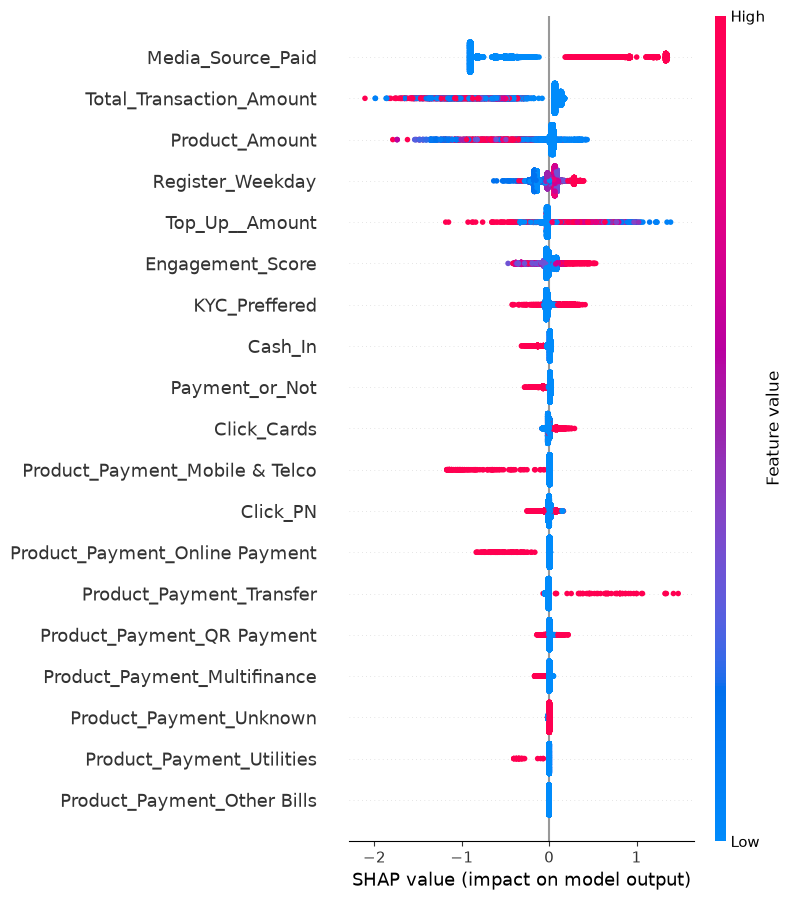

In [44]:
shap.summary_plot(shap_values, X_test)

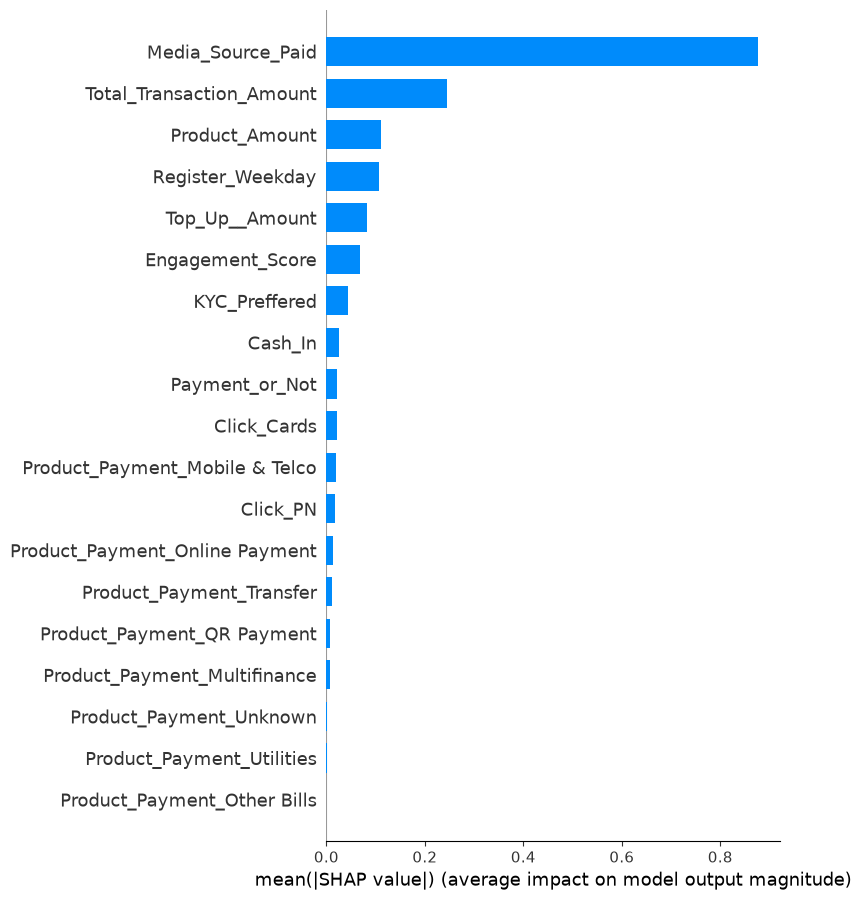

In [45]:
shap.summary_plot(shap_values, X_test, plot_type="bar")

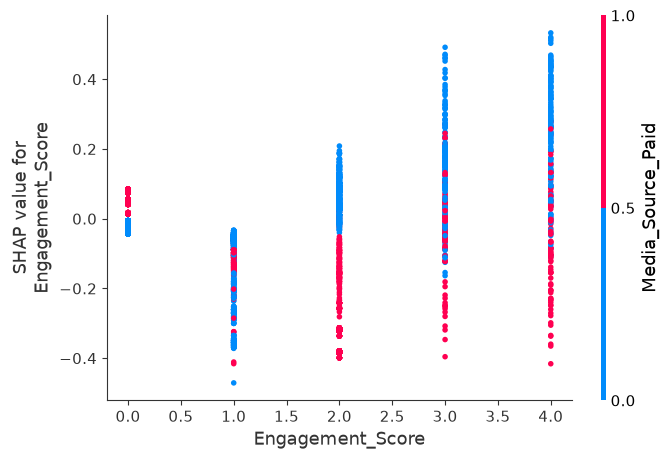

In [46]:
shap.dependence_plot("Engagement_Score", shap_values, X_test)

In [47]:
# Supaya komputasi lebih ringan, gunakan sample dari data train sebagai background
X_background = X_train.sample(min(200, len(X_train)), random_state=42)

# Convert boolean columns to int for SHAP compatibility
# Identify boolean columns in X_train and convert them to int (0 or 1)
boolean_cols = X_train.select_dtypes(include='bool').columns
if not boolean_cols.empty:
    X_background[boolean_cols] = X_background[boolean_cols].astype(int)
    X_test[boolean_cols] = X_test[boolean_cols].astype(int)

# TreeExplainer cocok untuk XGBoost / model tree-based
explainer = shap.TreeExplainer(final_model, X_background)

# Hitung SHAP values pada test set
shap_values = explainer(X_test)

print("Shape SHAP values:", shap_values.values.shape)
print("Shape X_test:", X_test.shape)

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


 48%|==========          | 4841/10000 [00:11<00:11]       

 53%|===========         | 5280/10000 [00:12<00:10]       

 57%|===========         | 5717/10000 [00:13<00:09]       

 62%|============        | 6189/10000 [00:14<00:08]       

 67%|=============       | 6671/10000 [00:15<00:07]       

... (3 outputs left out)

 86%|=================   | 8582/10000 [00:19<00:03]       

 90%|==================  | 9044/10000 [00:20<00:02]       

 95%|=================== | 9530/10000 [00:21<00:01]       

Shape SHAP values: (10000, 19)
Shape X_test: (10000, 19)


 Global explanation: fitur paling berpengaruh

a. SHAP summary plot (beeswarm)
Ini paling bagus untuk lihat fitur mana yang paling mendorong uninstall / tidak uninstall secara global.

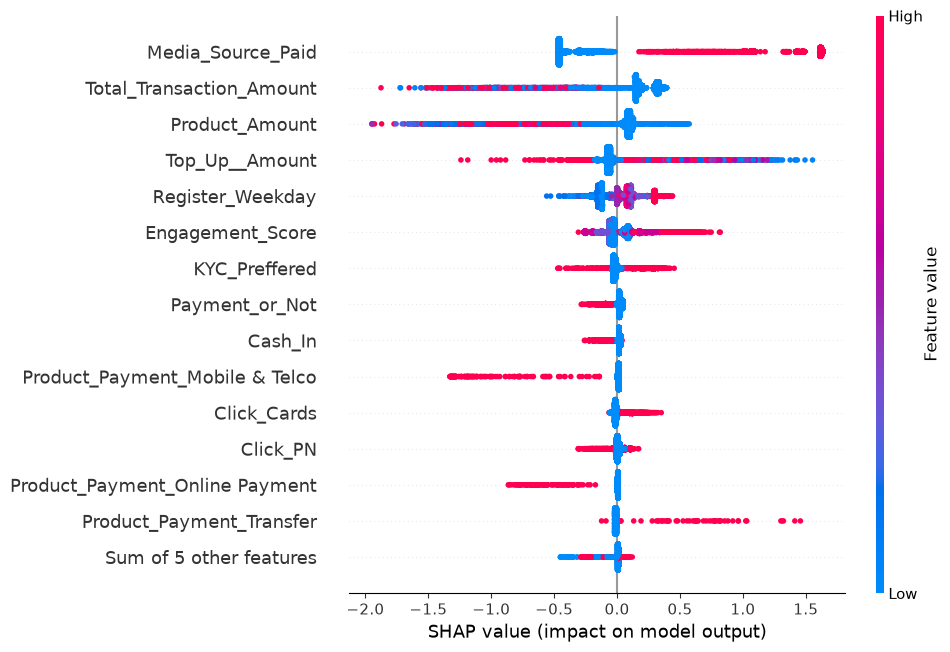

In [48]:
shap.plots.beeswarm(shap_values, max_display=15)

b. SHAP bar plot

Versi yang lebih ringkas untuk ranking fitur.

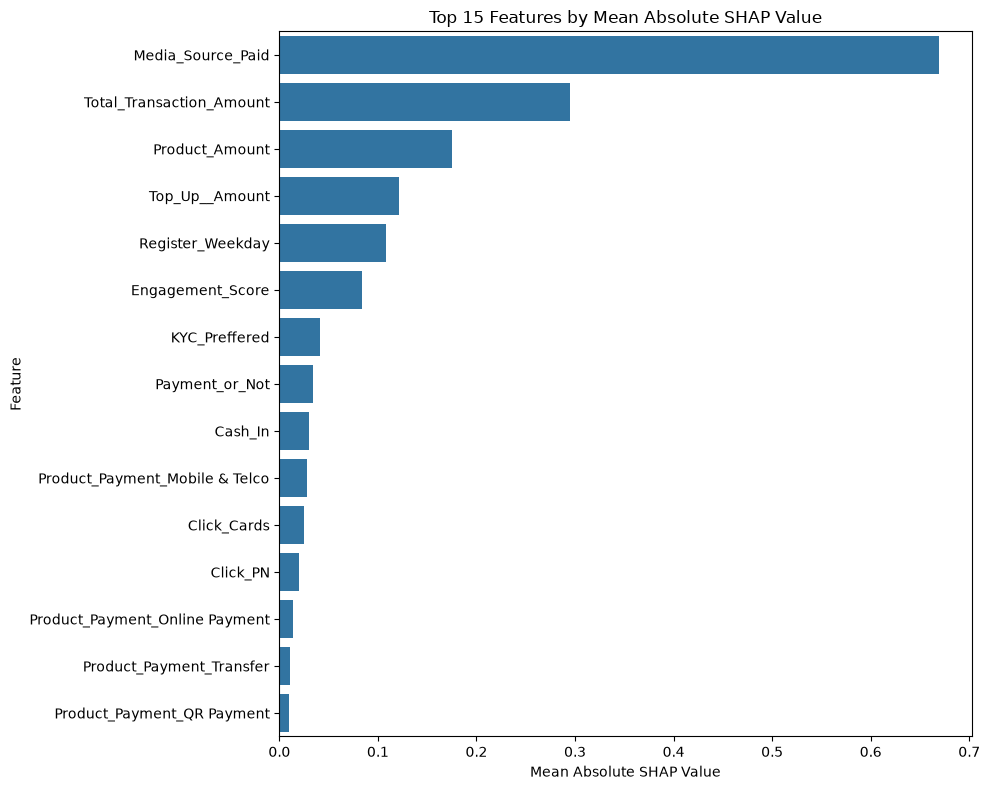

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# Define shap_importance here before it's used
shap_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "MeanAbsSHAP": np.abs(shap_values.values).mean(axis=0)
}).sort_values(by="MeanAbsSHAP", ascending=False)

top_features = shap_importance.head(15)

plt.figure(figsize=(10, 8))
sns.barplot(x='MeanAbsSHAP', y='Feature', data=top_features)
plt.title('Top 15 Features by Mean Absolute SHAP Value')
plt.xlabel('Mean Absolute SHAP Value')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

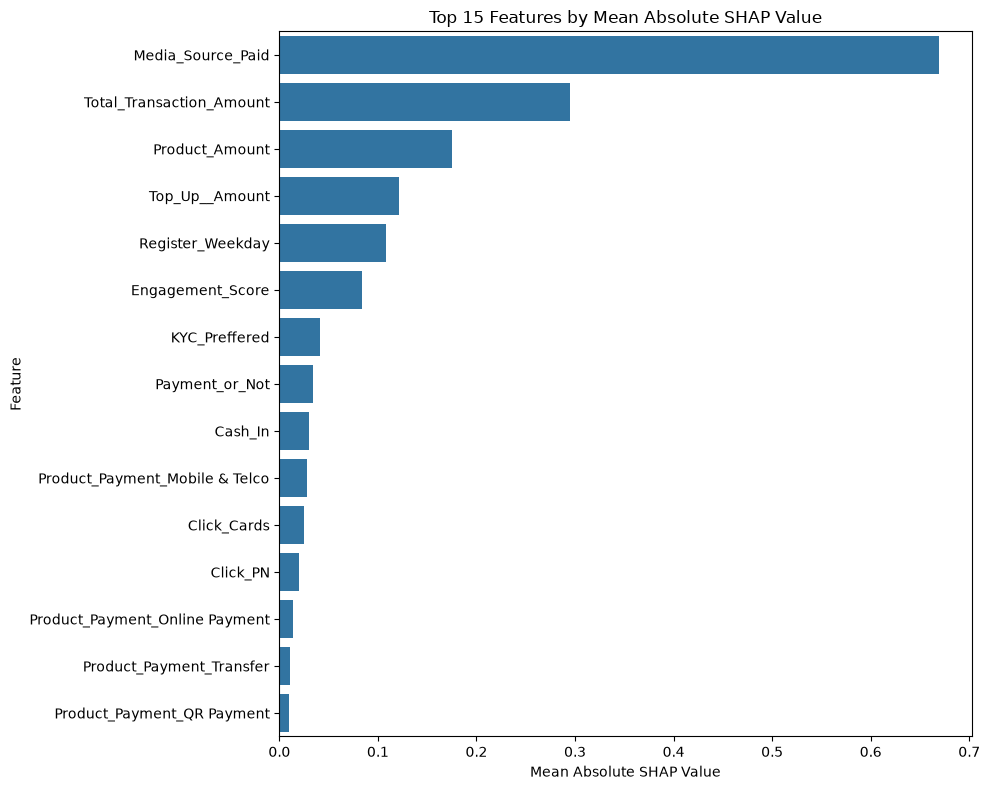

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# Define shap_importance here before it's used
shap_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "MeanAbsSHAP": np.abs(shap_values.values).mean(axis=0)
}).sort_values(by="MeanAbsSHAP", ascending=False)

top_features = shap_importance.head(15)

plt.figure(figsize=(10, 8))
sns.barplot(x='MeanAbsSHAP', y='Feature', data=top_features)
plt.title('Top 15 Features by Mean Absolute SHAP Value')
plt.xlabel('Mean Absolute SHAP Value')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

Local explanation: alasan prediksi 1 user tertentu

Contoh lihat user ke-0 di test set.

Prediksi probabilitas uninstall: 0.29511067
Label aktual: 0


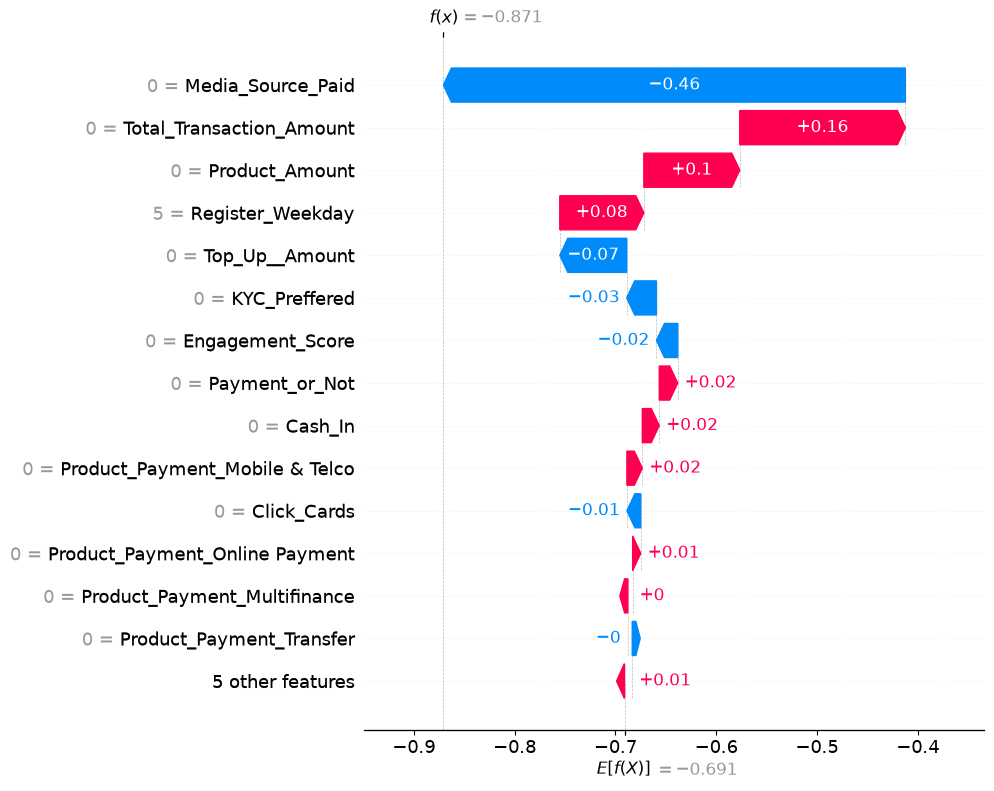

In [51]:
idx = 0

print("Prediksi probabilitas uninstall:", final_model.predict_proba(X_test.iloc[[idx]])[0, 1])
print("Label aktual:", y_test.iloc[idx])

shap.plots.waterfall(shap_values[idx], max_display=15)

Kalau mau pilih user yang benar-benar diprediksi berisiko tinggi uninstall:

Index test: 22
Probabilitas uninstall: 0.8663116
Label aktual: 0


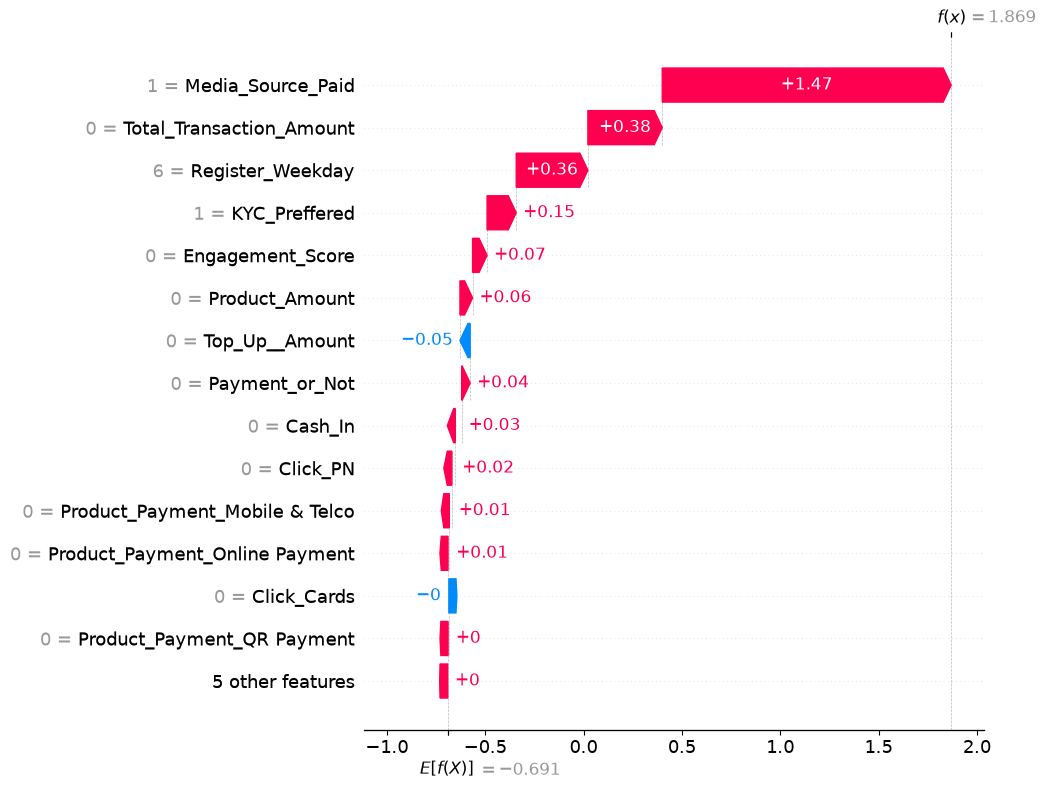

In [52]:
proba_test = final_model.predict_proba(X_test)[:, 1]

# Ambil index user dengan probabilitas uninstall tertinggi
idx = np.argmax(proba_test)

print("Index test:", idx)
print("Probabilitas uninstall:", proba_test[idx])
print("Label aktual:", y_test.iloc[idx])

shap.plots.waterfall(shap_values[idx], max_display=15)

In [53]:
shap_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "MeanAbsSHAP": np.abs(shap_values.values).mean(axis=0)
}).sort_values(by="MeanAbsSHAP", ascending=False)

shap_importance.head(15)

,Feature,MeanAbsSHAP
6,Media_Source_Paid,0.668935
17,Total_Transaction_Amount,0.295350
5,Product_Amount,0.175325
3,Top_Up__Amount,0.120903
18,Register_Weekday,0.108035
16,Engagement_Score,0.083879
7,KYC_Preffered,0.041246
4,Payment_or_Not,0.034440
2,Cash_In,0.029781
8,Product_Payment_Mobile & Telco,0.027922


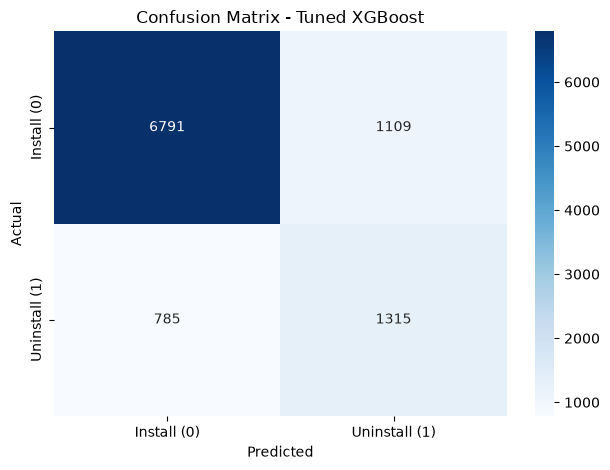

In [54]:
# Confusion Matrix Heatmap
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, RocCurveDisplay

cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Install (0)', 'Uninstall (1)'],
            yticklabels=['Install (0)', 'Uninstall (1)'])
plt.title('Confusion Matrix - Tuned XGBoost')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

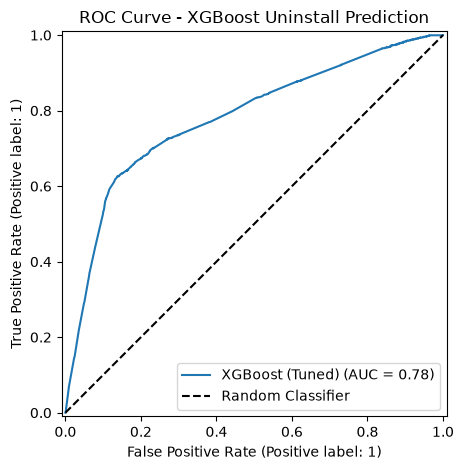

In [55]:
# ROC Curve
RocCurveDisplay.from_predictions(
    y_test, y_test_proba,
    name="XGBoost (Tuned)"
)
plt.plot([0,1],[0,1],'k--', label='Random Classifier')
plt.title('ROC Curve - XGBoost Uninstall Prediction')
plt.legend()
plt.tight_layout()
plt.show()

In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import xgboost as xgb

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve,
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [57]:
best_model = final_model

In [58]:
print(type(best_model))

<class 'xgboost.sklearn.XGBClassifier'>


In [59]:
report = classification_report(y_test, y_test_pred, output_dict=True)
df_report = pd.DataFrame(report).transpose()

print("Classification Report:")
print(df_report)

# Simpan jika perlu
df_report.to_csv("classification_report.csv", index=True)

Classification Report:
              precision    recall  f1-score     support
0              0.896383  0.859620  0.877617   7900.0000
1              0.542492  0.626190  0.581344   2100.0000
accuracy       0.810600  0.810600  0.810600      0.8106
macro avg      0.719438  0.742905  0.729480  10000.0000
weighted avg   0.822066  0.810600  0.815400  10000.0000


In [60]:
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       0.90      0.86      0.88      7900
           1       0.54      0.63      0.58      2100

    accuracy                           0.81     10000
   macro avg       0.72      0.74      0.73     10000
weighted avg       0.82      0.81      0.82     10000



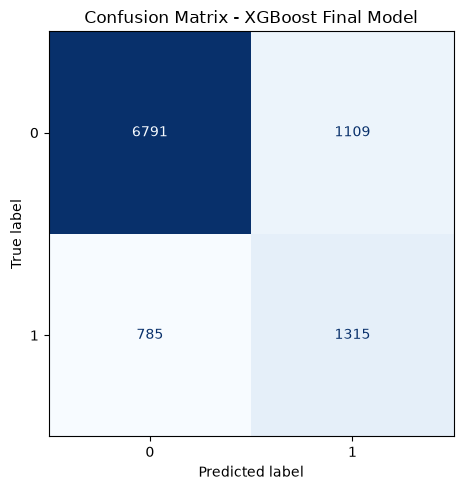

In [61]:
cm = confusion_matrix(y_test, y_test_pred)

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Confusion Matrix - XGBoost Final Model")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

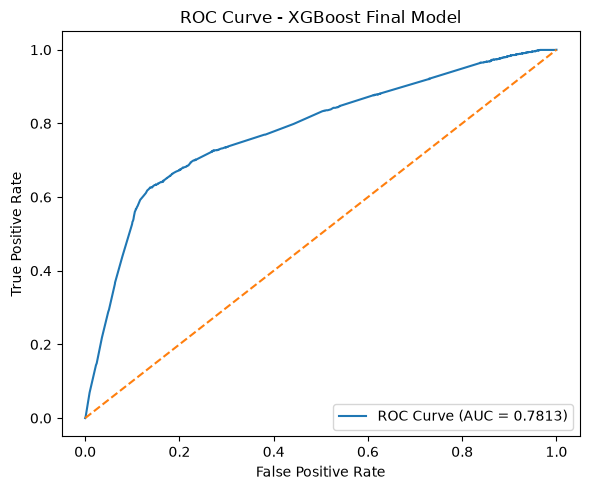

In [62]:
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)
auc_score = roc_auc_score(y_test, y_test_proba)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {auc_score:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - XGBoost Final Model")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()

In [63]:
metrics_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Value": [
        accuracy_score(y_test, y_test_pred),
        precision_score(y_test, y_test_pred),
        recall_score(y_test, y_test_pred),
        f1_score(y_test, y_test_pred),
        roc_auc_score(y_test, y_test_proba)
    ]
})

print(metrics_summary)
metrics_summary.to_csv("metrics_summary.csv", index=False)

      Metric     Value
0   Accuracy  0.810600
1  Precision  0.542492
2     Recall  0.626190
3   F1-score  0.581344
4    ROC-AUC  0.781345


<Figure size 800x600 with 0 Axes>

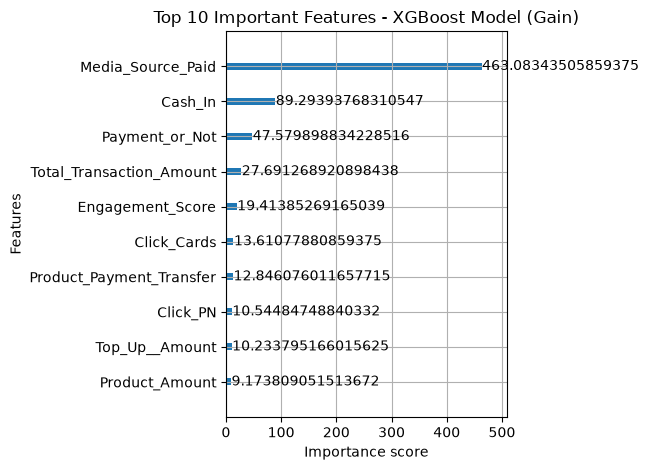

In [64]:
plt.figure(figsize=(8, 6))
xgb.plot_importance(best_model, importance_type="gain", max_num_features=10)
plt.title("Top 10 Important Features - XGBoost Model (Gain)")
plt.tight_layout()
plt.savefig("feature_importance_gain.png", dpi=300, bbox_inches="tight")
plt.show()

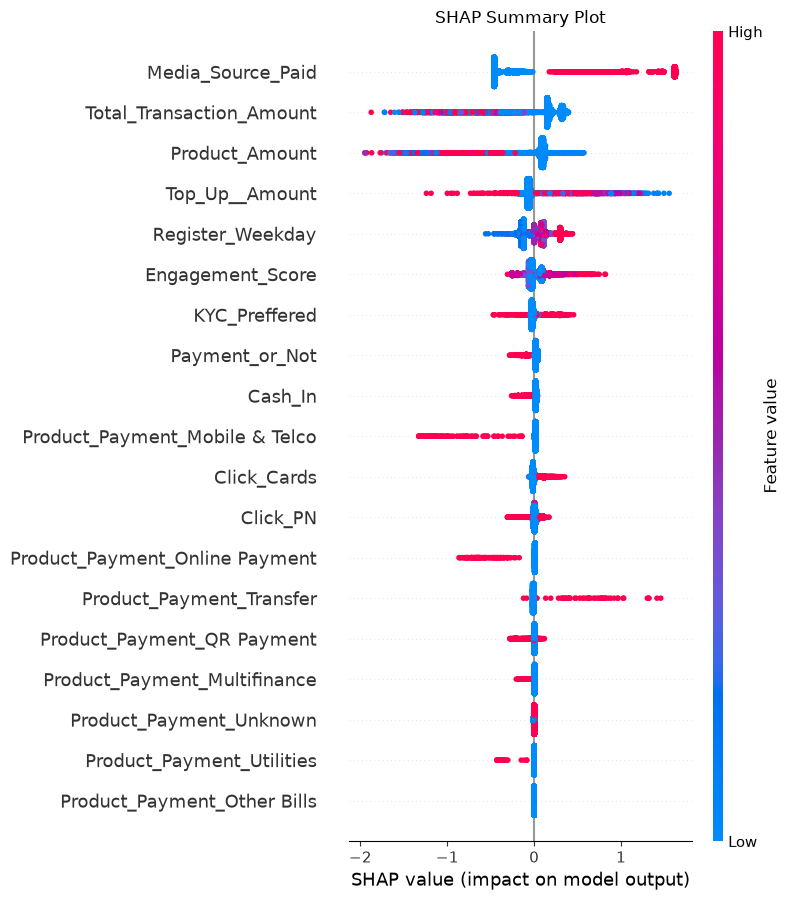

In [65]:
plt.figure()
shap.summary_plot(shap_values, X_test, show=False)
plt.title("SHAP Summary Plot")
plt.tight_layout()
plt.savefig("shap_summary_plot.png", dpi=300, bbox_inches="tight")
plt.show()

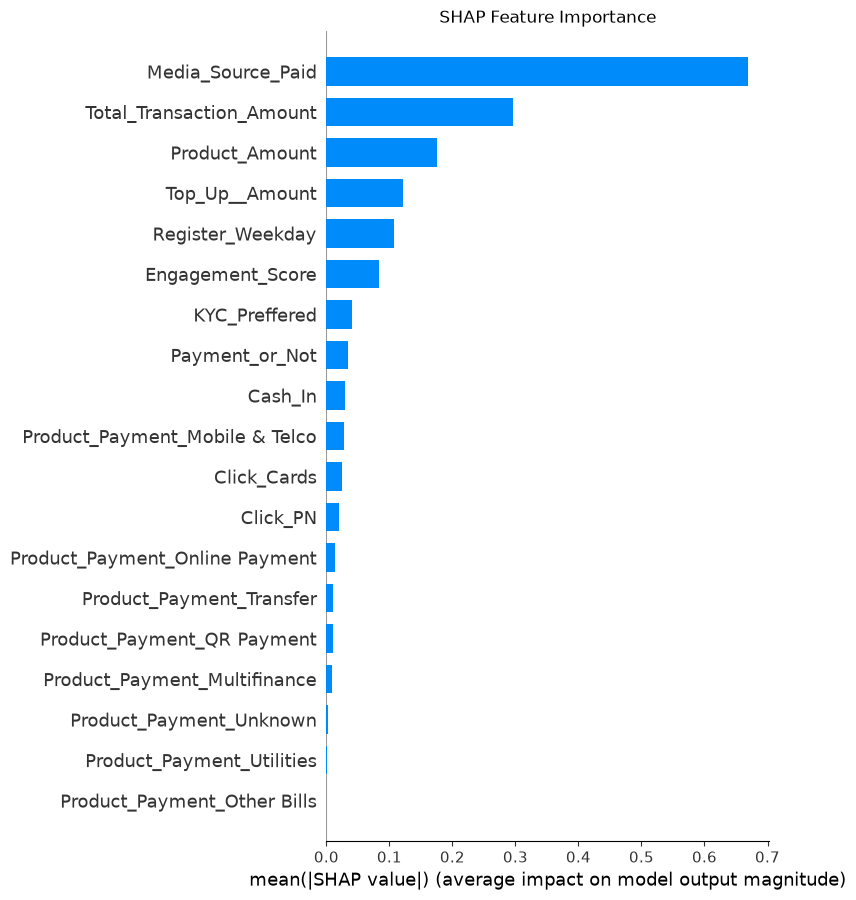

In [66]:
plt.figure()
shap.summary_plot(shap_values, X_test, plot_type="bar", show=False)
plt.title("SHAP Feature Importance")
plt.tight_layout()
plt.savefig("shap_bar_plot.png", dpi=300, bbox_inches="tight")
plt.show()

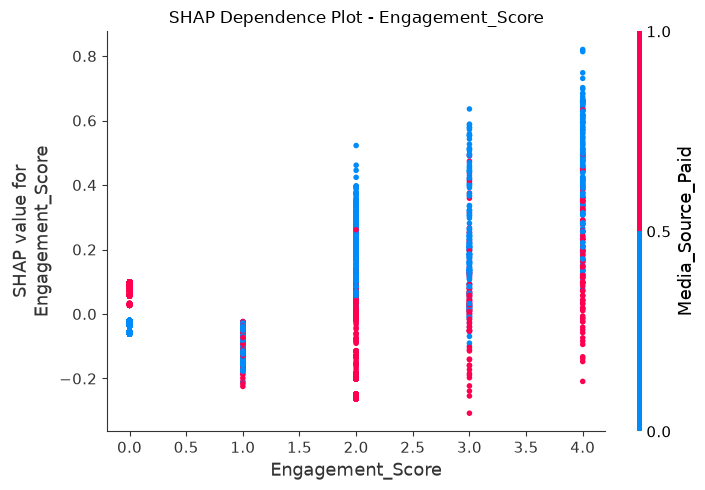

In [67]:
shap.dependence_plot(
    "Engagement_Score",
    shap_values.values,
    X_test,
    show=False
)
plt.title("SHAP Dependence Plot - Engagement_Score")
plt.tight_layout()
plt.savefig("shap_dependence_engagement_score.png", dpi=300, bbox_inches="tight")
plt.show()

In [68]:
shap.initjs()

force_plot = shap.force_plot(
    shap_values[0]
)

force_plot

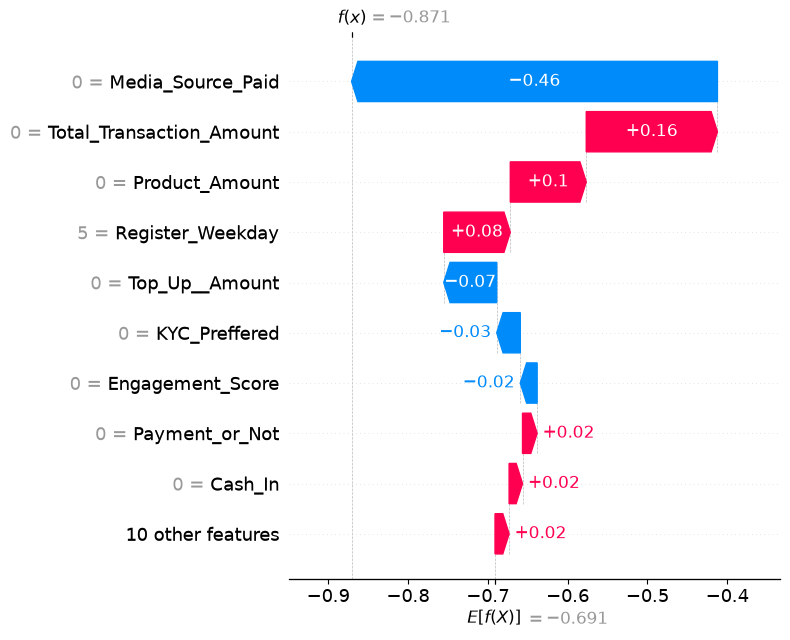

In [69]:
# Jika shap_values berupa array lama
sample_idx = 0
shap_explanation = shap.Explanation(
    values=shap_values.values[sample_idx],
    base_values=explainer.expected_value,
    data=X_test.iloc[sample_idx],
    feature_names=X_test.columns
)

plt.figure()
shap.plots.waterfall(shap_explanation, show=False)
plt.tight_layout()
plt.savefig("shap_waterfall_plot_sample0.png", dpi=300, bbox_inches="tight")
plt.show()

In [70]:
print("=== METRICS SUMMARY ===")
print(f"Accuracy : {accuracy_score(y_test, y_test_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_test_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_test_pred):.4f}")
print(f"F1-score : {f1_score(y_test, y_test_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_test_proba):.4f}")

=== METRICS SUMMARY ===
Accuracy : 0.8106
Precision: 0.5425
Recall   : 0.6262
F1-score : 0.5813
ROC-AUC  : 0.7813


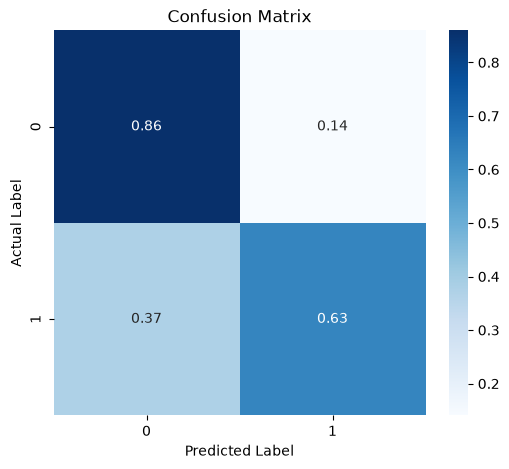

In [71]:
import seaborn as sns
import matplotlib.pyplot as plt

cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(6,5))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.show()

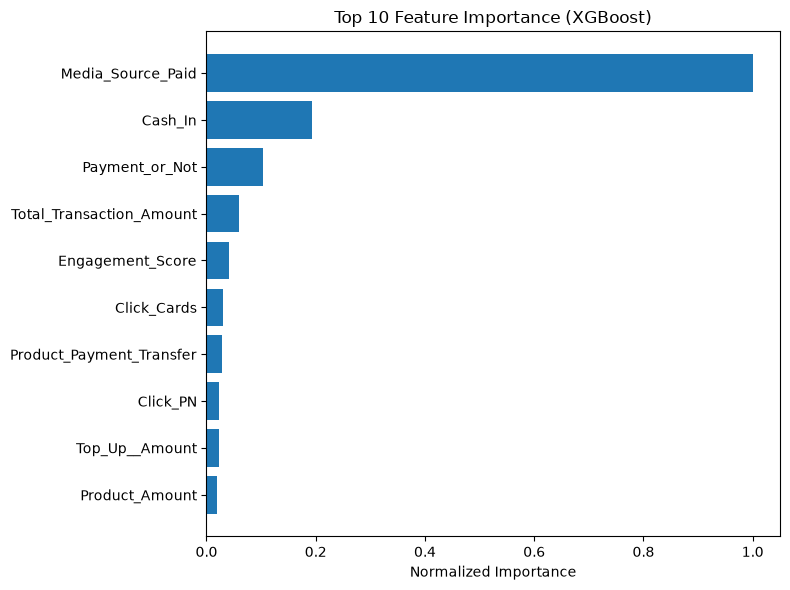

In [72]:
import matplotlib.pyplot as plt
import pandas as pd

# Ambil importance
importance = best_model.get_booster().get_score(importance_type='gain')

# Convert ke dataframe
df_imp = pd.DataFrame({
    'feature': list(importance.keys()),
    'importance': list(importance.values())
})

# Sort
df_imp = df_imp.sort_values(by='importance', ascending=False).head(10)

# Normalize (opsional)
df_imp['importance'] = df_imp['importance'] / df_imp['importance'].max()

# Plot
plt.figure(figsize=(8,6))
plt.barh(df_imp['feature'], df_imp['importance'])
plt.gca().invert_yaxis()
plt.xlabel("Normalized Importance")
plt.title("Top 10 Feature Importance (XGBoost)")
plt.tight_layout()
plt.show()